# How Audiences Engaged with COVID-19 News on YouTube

**Question:** How did audience engagement with COVID-19 coverage differ across four major English-language news publishers on YouTube (BBC News, CNN, Fox News, MSNBC)?

This notebook looks at four angles:

1. **Reach and engagement:** views, likes and comments per channel
2. **Engagement quality:** which videos earned the highest like-to-view ratio
3. **Audience response time:** how long after publication viewers commented
4. **Publishing cadence:** how often each channel posted COVID-19 videos

**Data:** ~200 videos (about 50 per channel) and ~4,400 comments collected with the YouTube Data API v3. Videos were found by searching titles for `coronavirus`, `covid`, `covid-19` and `pandemic`, published between Jan 2020 and Jan 2023. See `data/README.md` for details.

## 1. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
CHANNEL_ORDER = ["BBC News", "CNN", "Fox News", "MSNBC"]
PALETTE = dict(zip(CHANNEL_ORDER, sns.color_palette("Set2", 4)))
IMG_DIR = "images"

## 2. Load and prepare the data

In [2]:
videos = pd.read_csv("data/videos.csv")
comments = pd.read_csv("data/comments.csv")

print(f"Videos:   {len(videos):,} rows")
print(f"Comments: {len(comments):,} rows")

Videos:   200 rows
Comments: 4,463 rows


### Cleaning steps
- Parse timestamps as UTC so video and comment times can be compared directly.
- Convert ISO 8601 durations (e.g. `PT1H4M30S`) to seconds. A simple `PT(\d+)M(\d+)S` pattern mis-reads 9 of the 200 videos here (e.g. `PT51S`, `PT10M`, `PT3H32M41S`), so this parser handles hours and missing parts.
- Drop comments with no timestamp, since they can't be used for timing analysis.

In [3]:
def iso_duration_to_seconds(value):
    """Convert an ISO 8601 duration like 'PT1H4M30S' to seconds."""
    match = re.fullmatch(r"P(?:(\d+)D)?(?:T(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?)?", str(value))
    if not match:
        return np.nan
    days, hours, minutes, seconds = (int(x) if x else 0 for x in match.groups())
    return days * 86400 + hours * 3600 + minutes * 60 + seconds

videos["published_at"] = pd.to_datetime(videos["published_at"], utc=True)
videos["duration_sec"] = videos["duration"].apply(iso_duration_to_seconds)

comments["comment_date"] = pd.to_datetime(comments["comment_date"], utc=True)
comments = comments.dropna(subset=["comment_date"])

# Quick data quality check
print(videos.groupby("channel_title").agg(
    videos=("video_id", "count"),
    first_video=("published_at", "min"),
    last_video=("published_at", "max"),
))
print("\nMissing values in comments:")
print(comments.isna().sum()[comments.isna().sum() > 0])

               videos               first_video                last_video
channel_title                                                            
BBC News           50 2020-02-04 08:17:48+00:00 2021-05-12 11:15:02+00:00
CNN                50 2020-01-21 02:47:47+00:00 2021-02-25 00:24:36+00:00
Fox News           50 2020-02-25 02:20:00+00:00 2021-03-16 11:15:03+00:00
MSNBC              50 2020-03-01 20:30:16+00:00 2021-12-31 05:00:15+00:00

Missing values in comments:
comment_text           61
parent_comment_id    3899
dtype: int64


## 3. Reach and engagement by channel

Totals show overall share, but because each channel contributes a similar number of videos, the **median per video** is a fairer comparison. It isn't skewed by one viral upload.

Share of total engagement (%):
               Views  Likes  Comments
channel_title                        
BBC News        25.1   18.4      12.8
CNN             47.0   46.3      51.5
Fox News        14.6   23.1      21.7
MSNBC           13.2   12.3      14.0


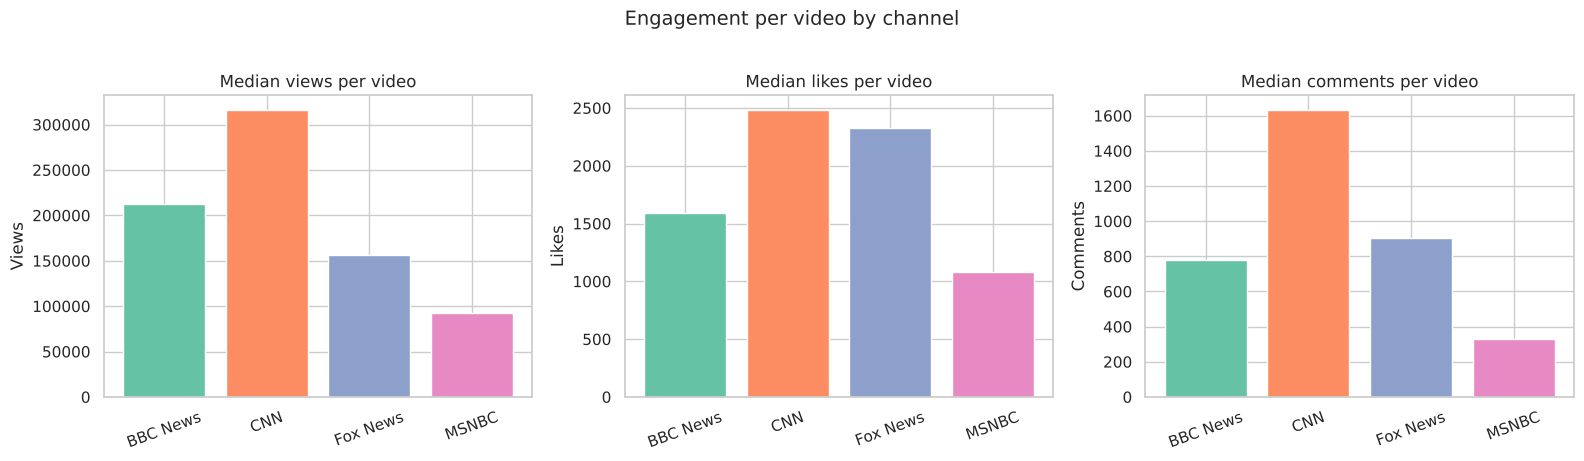

In [4]:
metrics = {"view_count": "Views", "like_count": "Likes", "comment_count": "Comments"}

totals = videos.groupby("channel_title")[list(metrics)].sum()
share = (totals / totals.sum() * 100).round(1)
print("Share of total engagement (%):")
print(share.rename(columns=metrics))

medians = videos.groupby("channel_title")[list(metrics)].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, metrics.items()):
    data = medians[col].reindex(CHANNEL_ORDER)
    ax.bar(data.index, data.values, color=[PALETTE[c] for c in data.index])
    ax.set_title(f"Median {label.lower()} per video")
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Engagement per video by channel", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/engagement_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **CNN leads on reach.** It holds 47% of total views, 46% of likes and 52% of comments, and its lead holds per video too: a median of about 316k views and 1.6k comments, against 212k and 780 for BBC.
- **Fox News punches above its views.** It has the second-lowest median views (about 156k) but a median of 2.3k likes per video, nearly level with CNN and well ahead of BBC (1.6k).
- **MSNBC trails on every measure**, with a median of about 93k views and 328 comments per video.

## 4. Which videos earned the most likes per view?

In [5]:
videos["like_view_ratio"] = videos["like_count"] / videos["view_count"].replace(0, np.nan)

top5 = (videos.nlargest(5, "like_view_ratio")
        [["channel_title", "video_title", "view_count", "like_count", "like_view_ratio", "url"]]
        .assign(like_view_ratio=lambda d: (d["like_view_ratio"] * 100).round(2))
        .rename(columns={"like_view_ratio": "likes_per_100_views"}))
display(top5)

print("Median likes per 100 views, by channel:")
print((videos.groupby("channel_title")["like_view_ratio"].median() * 100).round(2))

,channel_title,video_title,view_count,like_count,likes_per_100_views,url
45,Fox News,gym owners reflect on coronavirus pandemic one...,9163,285,3.11,https://www.youtube.com/watch?v=bf4WRdPnf4I
156,MSNBC,answering your questions about the coronavirus...,4128,122,2.96,https://www.youtube.com/watch?v=QwGfY5CJJZ0
49,Fox News,pfizer claims to have effective coronavirus v...,70713,1950,2.76,https://www.youtube.com/watch?v=gYGbAwosG1k
26,Fox News,steve hilton on the longterm consequences of c...,32891,865,2.63,https://www.youtube.com/watch?v=3ebpS88BAwA
43,Fox News,dni ratcliffe coronavirus pandemic created opp...,60843,1485,2.44,https://www.youtube.com/watch?v=N9TdWNrTLF8


Median likes per 100 views, by channel:
channel_title
BBC News    0.78
CNN         0.85
Fox News    1.59
MSNBC       1.07
Name: like_view_ratio, dtype: float64


**Observations**
- **4 of the top 5 videos are from Fox News** (the other is MSNBC). The top videos earn 2.4 to 3.1 likes per 100 views.
- **This isn't just a few outliers.** Fox's median is 1.59 likes per 100 views, about double BBC (0.78) and CNN (0.85). Its audience is smaller but more likely to actively engage.
- The highest ratios come from relatively small videos (4k to 71k views), which suggests a loyal core audience rather than broad reach.

## 5. How quickly do viewers comment?

Response time = time between a video being published and a comment being posted. It's shown in **days** on a log scale, because it ranges from minutes to years.

**Important:** the collection script fetched only the first page of comment threads per video (YouTube's default order is newest first, about 20 threads). So these are mostly the *latest* comments each video had at collection time. This measures **how long commenting kept going after publication**, not how fast a typical viewer responds.

Comment response time (days):
                Q1  median     Q3    IQR
channel_title                           
BBC News       8.2   150.5  673.3  665.0
CNN            6.0    82.8  358.9  352.8
Fox News       1.0     4.9   37.3   36.4
MSNBC          0.4     1.6    5.2    4.8


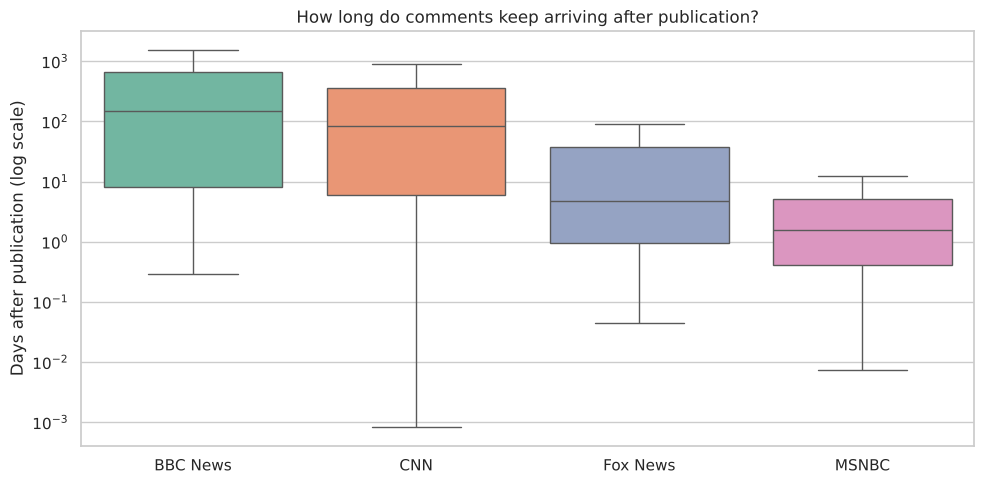

In [6]:
vc = videos.merge(comments, on="video_id", how="inner")
vc["response_days"] = (vc["comment_date"] - vc["published_at"]).dt.total_seconds() / 86400
vc = vc[vc["response_days"] > 0]

summary = (vc.groupby("channel_title")["response_days"]
           .quantile([0.25, 0.5, 0.75]).unstack()
           .rename(columns={0.25: "Q1", 0.5: "median", 0.75: "Q3"}))
summary["IQR"] = summary["Q3"] - summary["Q1"]
print("Comment response time (days):")
print(summary.reindex(CHANNEL_ORDER).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=vc, x="channel_title", y="response_days", order=CHANNEL_ORDER,
            hue="channel_title", palette=PALETTE, legend=False, showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set_title("How long do comments keep arriving after publication?")
ax.set_xlabel("")
ax.set_ylabel("Days after publication (log scale)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/comment_response_time.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- For MSNBC and Fox News, even the latest comments sit close to publication, with medians of about **1.6 days** and **4.9 days**. Commenting on these videos dies out quickly.
- BBC News and CNN videos were still attracting comments months later, with medians of about **150 days** and **82 days**. BBC also has the widest spread (IQR of about 665 days, against under 5 for MSNBC).
- This suggests BBC and CNN COVID videos keep being found long after release, through search or recommendations, while MSNBC and Fox engagement is tied to the news cycle.
- Because only the newest comments were collected, treat this as a measure of comment lifespan, not typical response speed.

## 6. How often does each channel publish?

channel_title
BBC News    0.75
CNN         0.86
Fox News    0.89
MSNBC       0.52
Name: videos, dtype: float64


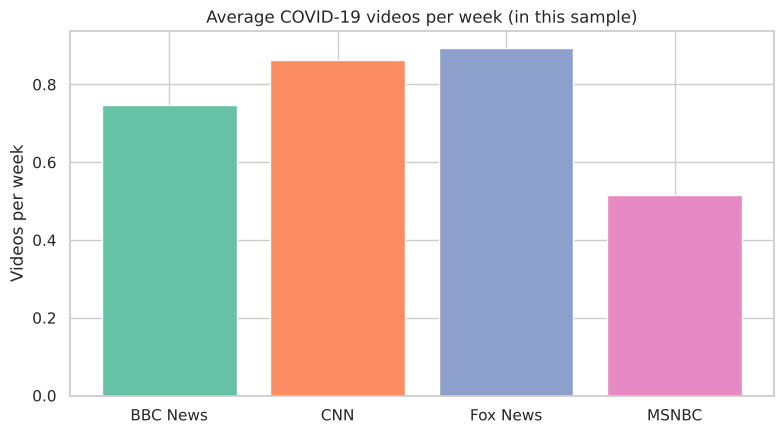

In [7]:
weekly = (videos.set_index("published_at")
          .groupby("channel_title")
          .resample("W").size()
          .rename("videos")
          .reset_index())
avg_weekly = weekly.groupby("channel_title")["videos"].mean().reindex(CHANNEL_ORDER)
print(avg_weekly.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(avg_weekly.index, avg_weekly.values, color=[PALETTE[c] for c in avg_weekly.index])
ax.set_title("Average COVID-19 videos per week (in this sample)")
ax.set_ylabel("Videos per week")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/videos_per_week.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- In this sample, Fox News (0.89) and CNN (0.86) average close to one COVID video per week, BBC slightly fewer (0.75), and MSNBC about one every two weeks (0.52).
- **Caveat:** each channel was capped at about 50 videos, so this mostly reflects how spread out those 50 videos are over time, not each channel's true output.

## 7. Limitations
- **Sample, not census:** about 50 videos per channel from keyword search. The YouTube API ranks search results, so this isn't a random sample of each channel's COVID coverage.
- **Partial comments:** only the first page of comment threads (about 20, newest first) and the first page of replies were collected per video. 4 videos had comments disabled.
- **Pre-processed text:** comment text and video titles were lowercased, with punctuation, digits and English stopwords removed, and non-English comments filtered out during collection. Text-based analysis (e.g. sentiment) would need the raw text.
- **Snapshot in time:** view and like counts are as of collection date. Older videos have had more time to accumulate engagement.

## 8. Next steps
- Sentiment analysis of comment text by channel
- Overlay key pandemic events (e.g. WHO declaration, vaccine rollout) on comment volume over time
- Test whether video duration relates to engagement